<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-04-automl.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "AutoML"
bibliography:
  - refs/refs.bib
---

## The Problem: Hyperparameter Optimization

A learning algorithm fits **parameters** (for example, regression coefficients) from data.

**Hyperparameters** configure that fitting process: regularization strength, tree depth, or learning rate. We must choose them before fitting each candidate.

Given training data $D_{\mathrm{tr}}$, a fixed learning algorithm $A$, and a search space $\Lambda$, hyperparameter optimization (HPO) solves

$$\lambda^* \in \arg\min_{\lambda\in\Lambda} f(\lambda), \qquad
f(\lambda)=\mathcal{L}_{D_{\mathrm{val}}}\!\left(A_\lambda(D_{\mathrm{tr}})\right).$$

Here $\mathcal L$ is a validation loss; for ROC AUC we can minimize $1-\mathrm{AUC}$.

- The objective is usually an expensive, noisy black box: evaluating it requires training a model.
- A low training loss alone does not identify the best hyperparameters.

References: [@feurer2019hyperparameter].

## HPO as an Optimizer–Learning-System Loop

![Optimizer proposes a configuration; the learning system trains and validates it and returns a loss. Source: Hutter and Vanschoren AutoML tutorial.](img/automl/figures/blackbox-hpo-loop.png)

The learning system fits model parameters; the optimizer changes hyperparameters. **Sample efficiency** asks how much validation improvement we obtain per expensive evaluation. **Cost efficiency** also accounts for unequal evaluation times.

| Algorithm | Hyperparameter | Domain |
| --- | --- | --- |
| Logistic regression | regularization strength `C` | positive continuous, often searched on a log scale |
| Random forest | number of trees, leaf size | integer |
| Gradient boosting | learning rate, leaf count, regularization | mixed continuous and integer |

Some choices activate others, so practical spaces can be conditional rather than simple Cartesian products.

## Define the Evaluation Before Searching

Choose the target, metric, split strategy, and hyperparameter ranges before running the optimizer. For $K$-fold cross-validation on the development data, use

$$\widehat f(\lambda)=\frac{1}{K}\sum_{k=1}^{K}
\mathcal L_{D_k}\!\left(A_\lambda(D_{-k})\right).$$

Fit scaling, imputation, feature selection, and resampling **inside each training fold**. Use group or temporal splits when the application requires them.

This notebook uses training, validation, and test partitions. Search and classroom comparisons use training/validation data; the final test cell is run only after decisions are frozen. Repeatedly choosing from test results would turn the test set into another validation set.

## Learning Outcomes

By the end of this 3-hour lab, you should be able to:

- Formulate HPO and Combined Algorithm Selection and Hyperparameter optimization (CASH).
- Define the evaluation protocol and feature transformations before searching.
- Implement grid and random search and explain random search's effective-dimension argument.
- Distinguish a trial budget from a time budget and interpret budget-aware search.
- Run the existing FLAML classification and regression examples and inspect their choices.
- Explain how full pipeline optimization extends learner selection.
- Compare human-centered, agent-based, and specification-driven automation using research papers.
- Run successive halving and inspect FLAML search spaces and logged anytime behavior.
- Translate human constraints into an executable, validation-based comparison.

## Reading Warm-Up

Optional background: the [Hutter–Vanschoren NeurIPS 2018 AutoML tutorial](https://www.automl.org/wp-content/uploads/2018/12/hutter-vanschoren-part1-2.pdf) and the AutoML book [@hutter2019automated]. The explanations in this notebook are self-contained.

Look for algorithm choice as a top-level hyperparameter, expensive black-box evaluations, random search as a baseline, and multi-fidelity allocation.

**Discussion:** if AutoML returns a high-scoring model, what evidence do you still need before trusting it?

## Grid Search: Enumerate a Cartesian Product {.scrollable}

Choose a finite set $G_j$ for each of $d$ hyperparameters. Grid search evaluates every point in

$$G=G_1\times\cdots\times G_d,\qquad N_{\mathrm{grid}}=\prod_{j=1}^d |G_j|.$$

For a random forest, 4 depths × 3 leaf sizes × 5 tree counts means 60 candidates, or 300 fits with 5-fold CV, before any final refit. With $m$ values in each dimension, the count grows as $m^d$.

Grid search is transparent and useful for small, carefully chosen spaces. Its resolution is fixed by the grid: values between grid points are never tried, and adding an unimportant dimension still multiplies the work.

The parameter names below follow the pipeline used later. With three `C` values and three class-weight choices there are nine candidates, or 27 fits under three-fold CV, plus a refit:

```python
param_grid = {
    "classifier__C": [0.001, 1.0, 1000.0],
    "classifier__class_weight": [None, "balanced", {0: 1, 1: 2}],
}
GridSearchCV(classification_baseline, param_grid, cv=3, scoring="roc_auc")
```

The runnable comparison below additionally fixes identical stratified folds for both search methods.

## Random Search: Sample Configurations {.scrollable}

Choose a sampling distribution $p(\lambda)$, draw $N$ independent candidates, evaluate each, and retain the candidate with the smallest validation loss:

$$\lambda_1,\ldots,\lambda_N\sim p(\lambda),\qquad
\widehat\lambda_N\in\arg\min_{\lambda_i}\widehat f(\lambda_i).$$

Use categorical distributions for discrete choices and often log-uniform distributions for positive scale parameters such as regularization strength. The distribution and bounds encode assumptions: a poor search space can defeat any optimizer.

Unlike grid search, the number of trials need not be a product of per-dimension resolutions. Random search is easy to interrupt or extend. It does not use earlier scores to propose later candidates.

The corresponding nine-trial baseline samples `C` continuously on a log scale while keeping the same class-weight options:

```python
param_distributions = {
    "classifier__C": loguniform(0.001, 1000.0),
    "classifier__class_weight": [None, "balanced", {0: 1, 1: 2}],
}
RandomizedSearchCV(
    classification_baseline, param_distributions, n_iter=9,
    cv=3, scoring="roc_auc", random_state=RANDOM_STATE,
)
```

These snippets introduce the APIs; execute the complete comparison after setup. Independent trials can be parallelized, although worker count and hardware then affect elapsed time.

## Why Can Random Search Work So Well?

If only one of two hyperparameters matters, a 3 × 3 grid spends nine trials on only three values of the important parameter. Nine continuous random samples typically explore nine distinct values. The advantage grows when a high-dimensional space has only a few influential dimensions.

Let a useful region have probability mass $p$ under the sampling distribution. With independent trials,

$$P(\text{at least one useful configuration in }N\text{ trials})=1-(1-p)^N.$$

For $p=0.05$, 59 trials give about a 95% chance of hitting that region. This is a sampling calculation, not a guarantee of generalization or of finding the global optimum.

[Bergstra and Bengio (2012), *Random Search for Hyper-Parameter Optimization*](https://www.jmlr.org/papers/v13/bergstra12a.html) provide theory and experiments supporting the effective-dimension argument. Random search is a strong baseline; tiny useful regions, parameter interactions, or informative adaptive proposals can change the comparison.

References: [@bergstra2012random].

## Visualizing Effective Dimensionality

![Nine grid points cover only three values of each coordinate; nine continuous random samples usually cover nine. Source: Bergstra and Bengio via the Hutter and Vanschoren tutorial.](img/automl/figures/random-vs-grid-search.png)

| Independent trials | Hit a region of mass 5% | Hit a region of mass 1% |
| --- | --- | --- |
| 20 | 64% | 18% |
| 60 | 95% | 45% |
| 300 | >99.9% | 95% |

The probability depends on the region's mass under the sampling distribution. A dimension-free formula does not make the distribution or the size of the useful region independent of dimensionality. Run the toy experiment after setup to see this mechanism in action.

# The Budget Problem

## The Budget Is Part of the Problem {.scrollable}

A **trial budget** limits the number of candidates. A **time budget** limits elapsed time. They are different: a deep forest can cost much more than a small linear model. Include CV folds, preprocessing, search overhead, and final refitting when reporting total cost.

For a sequential search history $H_N=\{(\lambda_i,r_i,\widehat f_i,c_i)\}_{i=1}^N$, a simplified resource constraint is

$$\sum_{i=1}^N c(\lambda_i,r_i)+c_{\mathrm{overhead}}+c_{\mathrm{refit}}\le B.$$

Here $r_i$ is fidelity (for example, sample size or epochs), $c$ is cost, and $B$ is the total budget. The optimizer chooses what to evaluate, at what fidelity, and when to stop. It returns the best observed candidate, rather than a certified global optimum.

Compare methods with the same data, metric, hardware, and resource accounting. Equal trial counts do not imply equal elapsed time. Report the requested budget **and measured elapsed time**; a library time limit is not a hard operating-system deadline.

## Anytime Performance Under a Budget

For completed trials with validation losses $f_i$ and completion times $t_i$, define the incumbent curve

$$f^*(\tau)=\min\{f_i:t_i\le\tau\},\qquad \tau\le B.$$

Before the first completed trial there is no incumbent. With a fixed evaluation protocol, the best observed loss cannot increase as trials finish. Plotting this curve against elapsed time reveals how quickly an optimizer becomes useful; plotting against trial count answers a different question.

Budget can also mean CPU/GPU hours, money, or energy. Wall-clock time depends on hardware and parallelism, so report the execution setting along with the curve.

## Spending the Budget: Adaptation and Fidelity

Adaptive search uses previous evaluations to choose later candidates; Bayesian optimization is one approach. Multi-fidelity search first uses cheaper approximations and then spends more resources on promising candidates.

For example, successive halving repeatedly removes weak candidates while increasing resources for survivors. [Li et al. (2018), *Hyperband*](https://www.jmlr.org/papers/v18/16-558.html) combine random configurations with adaptive resource allocation and early stopping.

Low-fidelity rankings can be misleading: a model that learns slowly may be discarded too early. FLAML uses its own cost-aware search and resource allocation; it should not be described as simply running Hyperband.

References: [@li2018hyperband].

## Beyond Random Search: Learning Where to Search

Bayesian optimization fits a surrogate to observed configuration/loss pairs and uses an acquisition function to balance exploring uncertain regions with exploiting promising ones. See [Snoek et al. (2012)](https://arxiv.org/abs/1206.2944).

SMAC uses random-forest surrogates for algorithm configuration, including categorical and conditional choices; see [Hutter et al. (2011)](https://doi.org/10.1007/978-3-642-25566-3_40). Evolutionary and local-search approaches instead modify candidate configurations. These methods use search history, unlike independent random sampling.

References: [@snoek2012practical; @hutter2011sequential].

## Successive Halving, Hyperband, and BOHB

[Jamieson and Talwalkar (2016)](https://proceedings.mlr.press/v51/jamieson16.html) study allocating resources to identify promising candidates. In successive halving with reduction factor 3:

| Round | Candidates | Resource per candidate | Total resource |
| --- | --- | --- | --- |
| 0 | 27 | 1 unit | 27 units |
| 1 | 9 | 3 units | 27 units |
| 2 | 3 | 9 units | 27 units |
| 3 | 1 | 27 units | 27 units |

Hyperband varies the initial breadth/resource tradeoff across halving brackets. [BOHB (Falkner et al., 2018)](https://proceedings.mlr.press/v80/falkner18a.html) combines model-based configuration sampling with Hyperband-style allocation. Constant work per round is an idealization: actual training cost need not grow linearly with resource, and implementations may refit promoted candidates.

References: [@jamieson2016nonstochastic; @falkner2018bohb].

## Multi-Fidelity and Combined Search: Research Figures

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/automl/figures/multifidelity-optimization.png)

Low fidelity is useful when it preserves enough of the high-fidelity ranking. It can also discard slow-starting or data-hungry models.

![Regret against wall-clock time in the cited BOHB experiments. Source: Falkner et al. via the Hutter and Vanschoren tutorial.](img/automl/figures/bohb-combined-search.png)

The BOHB figure illustrates the anytime/final-performance tradeoff in those experiments; it is not a universal ranking across tasks.

# AutoML and CASH

## What Is AutoML?

**Automated Machine Learning (AutoML)** automates choices in constructing and evaluating an ML solution, within a user-defined task, search space, metric, and budget. Depending on the system, these choices include preprocessing, features, learning algorithms, hyperparameters, and ensembles.

HPO fixes the learning algorithm and tunes its settings. AutoML can also choose the algorithm and parts of the pipeline. Humans still define success, admissible data, evaluation design, and operational constraints.

The next formalization captures a central AutoML subproblem: choosing a learner and its conditional hyperparameters together.

References: [@hutter2019automated].

## CASH: Combined Algorithm Selection and Hyperparameter Optimization

Let $\mathcal A=\{A_1,\ldots,A_M\}$ be candidate algorithms and $\Lambda_a$ the hyperparameter space of $A_a$. The **CASH** problem is

$$ (a^*,\lambda^*)\in\arg\min_{a\in\{1,\ldots,M\},\;\lambda\in\Lambda_a}
\frac{1}{K}\sum_{k=1}^{K}\mathcal L_{D_k}\!\left(A_{a,\lambda}(D_{-k})\right). $$

Its domain is a conditional union $\bigcup_a\{a\}\times\Lambda_a$, rather than one rectangular grid. A **root hyperparameter** selects the learner, activating only its associated space $\Lambda_a$. A forest activates tree-related settings; logistic regression activates regularization settings. A practical solver approximates this objective under a resource budget.

[Thornton et al. (2013), *Auto-WEKA: Combined Selection and Hyperparameter Optimization of Classification Algorithms*](https://arxiv.org/abs/1208.3719) introduced this formulation. CASH is the algorithm-selection problem; computation caching is a separate implementation technique.

References: [@thornton2013auto].

## CASH Search Spaces Are Conditional

| Learner selected at the root | Active hyperparameters | Inactive examples |
| --- | --- | --- |
| Random forest | tree count, tree/leaf constraints | logistic regularization strength |
| Logistic regression | penalty and regularization strength | forest depth and number of trees |
| Gradient boosting | learning rate, iterations, tree constraints | unrelated learners' settings |

The representation is a conditional tree or graph, not an unrestricted Cartesian product of every learner's settings. Inactive coordinates do not define different effective models.

CASH inherits HPO's expensive evaluations and adds learner-level allocation: **which algorithm deserves the next unit of budget?** Different learners and configurations have different costs; the answer should depend on observed quality, cost, and remaining resources.

## Two AutoML Systems: auto-sklearn and FLAML

| System | Main ideas in the cited paper | Connection to this lab |
| --- | --- | --- |
| auto-sklearn | Bayesian optimization of scikit-learn pipelines, meta-learning from earlier datasets, ensemble construction | Shows how CASH can include preprocessing and reuse experience |
| FLAML | Cost-aware learner selection, hyperparameter search, and sample-size allocation | Makes search under short time budgets easy to demonstrate |

Read [Feurer et al. (2015), *Efficient and Robust Automated Machine Learning*](https://papers.neurips.cc/paper_files/paper/2015/hash/11d0e6287202fced83f79975ec59a3a6-Abstract.html) and [Wang et al. (2021), *FLAML: A Fast and Lightweight AutoML Library*](https://arxiv.org/abs/1911.04706).

We use FLAML below, retaining the Adult Income and California Housing workflow. This is a teaching demonstration, not a benchmark establishing a winner between libraries.

References: [@feurer2015efficient; @wang2021flaml].

## auto-sklearn: Pipeline Search, Meta-Learning, and Ensembles {.scrollable}

The original auto-sklearn searches a fixed template: data preprocessing → feature preprocessing → classifier. The 2015 paper reports 15 classifiers, 14 feature preprocessors, and 4 data preprocessors, giving a conditional space with 110 hyperparameters; these describe that published version, rather than the current library inventory. SMAC proposes conditional configurations, meta-learning uses experience from similar datasets to initialize search, and ensemble construction reuses evaluated models.

[Feurer et al. (2022), *Auto-sklearn 2.0: Hands-free AutoML via Meta-Learning*](https://jmlr.org/papers/v23/21-0992.html) extend this approach with a portfolio of initial configurations, successive-halving allocation, and learned selection of model-selection policies. These are version-specific design choices, rather than capabilities of every AutoML system.

References: [@feurer2022auto].

## FLAML: What Makes Search Economical?

FLAML coordinates learner selection with the cost and expected benefit of further search. Low-cost initial configurations and cost-related settings help it start cheaply, while sample size can serve as another resource dimension.

[Cost-Frugal Optimization (CFO), Wu et al. (2021)](https://ojs.aaai.org/index.php/AAAI/article/view/17239) uses randomized local search starting from inexpensive configurations. [BlendSearch, Wang et al. (2021)](https://www.microsoft.com/en-us/research/publication/economical-hyperparameter-optimization-with-blended-search-strategy/) blends local and global search. Search and resampling behavior depend on configuration and version: this lab explicitly fixes the holdout split and learner lists.

Both auto-sklearn and FLAML offer configurable behavior. Avoid interpreting the comparison as “ensembles versus single models” or a guaranteed accuracy ranking: FLAML also supports optional ensembling.

References: [@wu2021frugal; @wang2021economical].

## auto-sklearn versus FLAML

| Aspect | auto-sklearn | FLAML |
| --- | --- | --- |
| Search scope | Learners and preprocessing in a fixed template | Learners and their conditional settings in our example |
| Optimization | SMAC-based Bayesian optimization | Cost-frugal local search / BlendSearch |
| Prior knowledge | Meta-learning and initial portfolios | Low-cost initial configurations |
| Resource allocation | Successive halving in version 2.0 | Cost-aware learner choice and sample-size allocation |
| Typical output | Ensemble of evaluated pipelines | Best model; optional ensembling |

These describe the cited systems and their configurable behavior [@feurer2015efficient; @feurer2022auto; @wang2021flaml]. They do not establish an accuracy ranking. Our lab fixes holdout validation, learner lists, and a short time budget so the choices remain inspectable.

# Practical Search and FLAML

## 1. Setup

If you run this lab in Google Colab or a minimal Python environment, run the following cell first.

The setup cell installs only missing packages. The primary datasets are real public datasets; if network access is unavailable, the notebook falls back to real built-in scikit-learn datasets so the lab remains runnable.

In [1]:
#| echo: false
# Install only packages missing from the current runtime.
import importlib.util
import subprocess
import sys

required_packages = ["flaml", "matplotlib", "numpy", "pandas", "scipy", "sklearn"]
missing_packages = [pkg for pkg in required_packages if importlib.util.find_spec(pkg) is None]

# Check AutoML runtime extras before importing FLAML, avoiding a cached
# partial import when a base installation needs additional dependencies.
if any(importlib.util.find_spec(pkg) is None for pkg in ["xgboost", "lightgbm"]):
    if "flaml" not in missing_packages:
        missing_packages.append("flaml")

if missing_packages:
    pip_names = []
    for pkg in missing_packages:
        if pkg == "sklearn":
            pip_names.append("scikit-learn")
        elif pkg == "flaml":
            pip_names.append("flaml[automl]")
        else:
            pip_names.append(pkg)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *pip_names])

time_budget = 30  # seconds per main FLAML run; use 5 for a quick smoke run
budget_values = [5, 15, 30]
CLASSIFIERS = ["rf", "extra_tree", "lrl2"]
REGRESSORS = ["rf", "extra_tree"]

In [2]:
#| echo: false
# Import data, modeling, preprocessing, evaluation, and plotting tools.
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from flaml import AutoML
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_california_housing, fetch_openml, load_diabetes
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestRegressor
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
)
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
#| echo: false
# Keep OneHotEncoder compatible with recent and older scikit-learn versions.
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    def root_mean_squared_error(y_true, y_pred):
        return np.sqrt(mean_squared_error(y_true, y_pred))


def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def evaluate_classifier(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = y_pred
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "roc_auc": roc_auc_score(y_eval, y_score),
        "f1": f1_score(y_eval, y_pred),
    }


def evaluate_regressor(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "rmse": root_mean_squared_error(y_eval, y_pred),
        "mae": mean_absolute_error(y_eval, y_pred),
        "r2": r2_score(y_eval, y_pred),
    }


def display_scores(label, scores):
    print(label)
    for name, value in scores.items():
        print(f"  {name:8s}: {value:.3f}")

## Demo: Grid versus Random on a Toy Function

The next loss depends strongly on the first coordinate and weakly on the second. Compare a fixed nine-point grid with 1,000 repetitions of nine random trials. The contour plot shows search coverage; the printed win fraction summarizes repeated random searches.

This deliberately constructed example illustrates low effective dimensionality. Moving the optimum or changing the grid can change the outcome.

Grid search (9 trials, 3 distinct l1 values): best loss = 0.803
Random search (9 trials, 9 distinct l1 values): median best loss = 0.096
Random search beats the grid in 98% of the repetitions


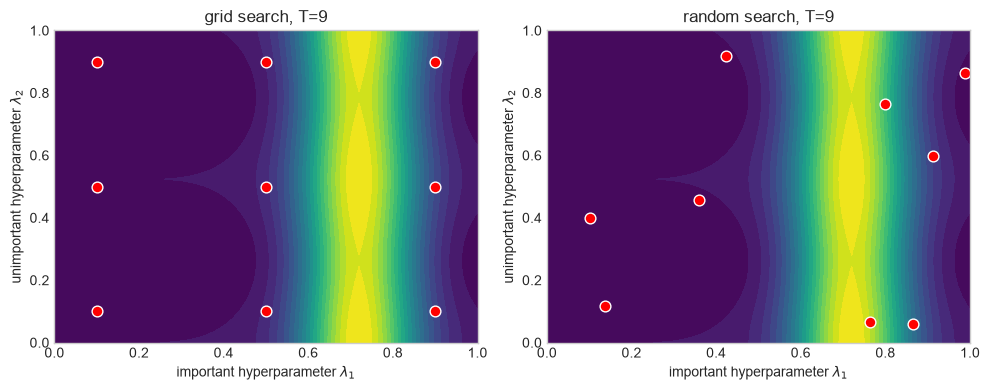

In [ ]:
#| echo: false
def toy_objective(l1, l2):
    """Validation loss: depends strongly on l1, weakly on l2. Minimum near l1=0.72."""
    return 1 - np.exp(-((l1 - 0.72) ** 2) / 0.02) + 0.05 * np.sin(6 * l2) ** 2


rng = np.random.default_rng(RANDOM_STATE)
T = 9
side = np.linspace(0.1, 0.9, int(np.sqrt(T)))
G1, G2 = np.meshgrid(side, side)
grid_best = toy_objective(G1, G2).min()

random_best = np.array([
    toy_objective(rng.uniform(0, 1, T), rng.uniform(0, 1, T)).min() for _ in range(1000)
])

print(f"Grid search ({T} trials, {len(side)} distinct l1 values): best loss = {grid_best:.3f}")
print(f"Random search ({T} trials, {T} distinct l1 values): median best loss = {np.median(random_best):.3f}")
print(f"Random search beats the grid in {(random_best < grid_best).mean():.0%} of the repetitions")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
for ax, (title, p1, p2) in zip(axes, [("grid", G1.ravel(), G2.ravel()),
                                      ("random", rng.uniform(0, 1, T), rng.uniform(0, 1, T))]):
    ax.contourf(xx, yy, toy_objective(xx, yy), levels=20, cmap="viridis_r")
    ax.scatter(p1, p2, c="red", edgecolor="white", s=60)
    ax.set_title(f"{title} search, T={T}")
    ax.set_xlabel("important hyperparameter $\\lambda_1$")
    ax.set_ylabel("unimportant hyperparameter $\\lambda_2$")
plt.tight_layout()
plt.show()

## 2. Classification Dataset

The first real dataset is Adult Census Income from the UCI repository, loaded through OpenML.

The task is to predict whether a person earns more than 50K USD per year from demographic and work-related attributes.

## Why This Dataset Works

Adult Income is a useful AutoML teaching case because it includes:

- mixed numerical and categorical variables;
- missing values;
- class imbalance;
- a socially sensitive target.

Those properties make model selection more realistic than a tiny built-in dataset.

The offline breast-cancer fallback has different features and predicts its provided benign/malignant label; the variable name `income` is retained only to reuse the workflow. Report the actual dataset and target, and adapt the discussion accordingly.

In [ ]:
#| echo: false
def load_adult_income(n_rows=8000):
    try:
        adult = fetch_openml("adult", version=2, as_frame=True)
        df = adult.frame.copy()
        df.columns = [c.strip().lower().replace("-", "_") for c in df.columns]
        if "class" in df.columns:
            df = df.rename(columns={"class": "income"})
        df = df.replace("?", np.nan).dropna()
        df["income"] = df["income"].astype(str).str.replace(".", "", regex=False).str.strip()
        df = df.sample(n=min(n_rows, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
        return df, "OpenML Adult Census Income"
    except Exception as exc:
        from sklearn.datasets import load_breast_cancer

        print(f"Could not download Adult from OpenML: {exc}")
        print("Falling back to the real built-in breast cancer dataset.")
        cancer = load_breast_cancer(as_frame=True)
        df = cancer.data.copy()
        df["income"] = cancer.target
        return df, "scikit-learn breast cancer fallback"


adult_df, adult_source = load_adult_income()
display(adult_df.head())
display(adult_df["income"].value_counts(normalize=True).rename("target_share").round(3))

OpenML Adult Census Income


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,19,Self-emp-not-inc,30800,10th,6,Married-spouse-absent,Adm-clerical,Unmarried,Amer-Indian-Eskimo,Female,0,0,40,United-States,<=50K
1,45,Private,26781,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,Amer-Indian-Eskimo,Male,0,0,40,United-States,<=50K
2,47,Private,431515,Assoc-voc,11,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,>50K
3,23,Private,45713,Some-college,10,Never-married,Craft-repair,Other-relative,White,Male,0,0,40,United-States,<=50K
4,53,Local-gov,175897,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K


income
<=50K    0.756
>50K     0.244
Name: target_share, dtype: float64

In [ ]:
#| echo: false
classification_target = "income"
X_cls = adult_df.drop(columns=[classification_target])
y_raw = adult_df[classification_target]
# Preserve the binary labels of the offline fallback dataset.
y_cls = (y_raw == ">50K").astype(int) if adult_source.startswith("OpenML") else y_raw.astype(int)
assert y_cls.nunique() == 2, "Classification requires two target classes."

X_cls_dev, X_cls_test, y_cls_dev, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls,
)

X_cls_train, X_cls_val, y_cls_train, y_cls_val = train_test_split(
    X_cls_dev, y_cls_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cls_dev
)

numeric_cls = X_cls_train.select_dtypes(include=np.number).columns.tolist()
categorical_cls = [c for c in X_cls_train.columns if c not in numeric_cls]

def prepare_flaml_frame(X, categorical_columns=None, category_maps=None):
    X_flaml = X.copy()
    categorical_columns = [] if categorical_columns is None else list(categorical_columns)
    categorical_columns = [column for column in categorical_columns if column in X_flaml.columns]
    category_maps = {} if category_maps is None else category_maps

    for column in categorical_columns:
        values = X_flaml[column].astype(object).where(X_flaml[column].notna(), "__missing__")
        if column not in category_maps:
            category_maps[column] = {value: code for code, value in enumerate(pd.unique(values))}
        unknown_code = len(category_maps[column])
        X_flaml[column] = values.map(category_maps[column]).fillna(unknown_code).astype("int32")

    X_flaml.columns = pd.RangeIndex(X_flaml.shape[1])
    return X_flaml, category_maps

X_cls_train_flaml, cls_category_maps = prepare_flaml_frame(X_cls_train, categorical_cls)
X_cls_val_flaml, _ = prepare_flaml_frame(X_cls_val, categorical_cls, cls_category_maps)
X_cls_test_flaml, _ = prepare_flaml_frame(X_cls_test, categorical_cls, cls_category_maps)

print(f"Rows: {len(X_cls)}")
print(f"Features: {X_cls.shape[1]}")
print(f"Numerical features: {len(numeric_cls)}")
print(f"Categorical features: {len(categorical_cls)}")
print(f"Positive class share: {y_cls.mean():.3f}")

Rows: 8000
Features: 14
Numerical features: 6
Categorical features: 8
Positive class share: 0.244


## 3. Manual Classification Baseline

We build a baseline with explicit preprocessing:

- numeric features are scaled;
- categorical features are one-hot encoded;
- logistic regression predicts the income label.

This baseline is intentionally simple, but it is strong enough to make the AutoML comparison meaningful.

Evaluate this baseline on the **validation partition**. The following grid/random candidates reuse this pipeline, fitting preprocessing separately inside each CV training fold.

In [7]:
classification_preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cls),
        ("cat", make_one_hot_encoder(), categorical_cls),
    ]
)

classification_baseline = Pipeline(
    steps=[
        ("preprocess", classification_preprocess),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

classification_baseline.fit(X_cls_train, y_cls_train)
classification_baseline_scores = evaluate_classifier(classification_baseline, X_cls_val, y_cls_val)
display_scores("Manual classification baseline", classification_baseline_scores)
print("confusion matrix:")
print(confusion_matrix(y_cls_val, classification_baseline.predict(X_cls_val)))

Manual classification baseline
  accuracy: 0.866
  roc_auc : 0.908
  f1      : 0.685
confusion matrix:
[[1153   57]
 [ 157  233]]


## Hands-On: Grid Search and Random Search {.scrollable}

Reuse the manual logistic-regression **pipeline**, so preprocessing is fitted inside each CV fold. Both searches perform nine candidates × three identical stratified folds, plus a refit. The grid uses three regularization strengths and three class-weight choices; random search draws regularization strengths on a log scale.

This is an equal-trial comparison, not an equal-time benchmark. Record both CV ROC AUC and elapsed time. FLAML below uses a holdout objective, so its `best_loss` is not directly comparable to these CV scores. A single run need not show random search winning.

In [ ]:
#| echo: false
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
weight_options = [None, "balanced", {0: 1, 1: 2}]
searches = {
    "grid": GridSearchCV(
        classification_baseline,
        {"classifier__C": [0.001, 1.0, 1000.0], "classifier__class_weight": weight_options},
        scoring="roc_auc", cv=cv, n_jobs=1,
    ),
    "random": RandomizedSearchCV(
        classification_baseline,
        {"classifier__C": loguniform(0.001, 1000.0), "classifier__class_weight": weight_options},
        n_iter=9, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=1,
    ),
}
search_rows = []
for name, search in searches.items():
    started_at = time.perf_counter()
    search.fit(X_cls_train, y_cls_train)
    search_rows.append({
        "search": name, "candidates": len(search.cv_results_["params"]),
        "cv_roc_auc": search.best_score_, "elapsed_seconds": time.perf_counter() - started_at,
        "validation_roc_auc": evaluate_classifier(search, X_cls_val, y_cls_val)["roc_auc"],
        "best_parameters": search.best_params_,
    })
pd.DataFrame(search_rows)

,search,candidates,cv_roc_auc,elapsed_seconds,validation_roc_auc,best_parameters
0,grid,9,0.898523,4.455957,0.908294,"{'classifier__C': 1.0, 'classifier__class_weig..."
1,random,9,0.898599,3.015543,0.908277,"{'classifier__C': 0.1767016940294795, 'classif..."


### Explain the Search Results

How many distinct `C` values did each method try? Which search spent more time? Does the best CV score agree with the external validation score? Explain why this experiment illustrates search behavior without proving a universal ranking of methods.

The next experiment makes the dimensionality issue more visible by varying four boosting hyperparameters. It supplements the compact logistic-regression example.

## Extended Demo: Four-Parameter Gradient Boosting Search {.scrollable}

Reuse the fold-safe preprocessing with a histogram gradient boosting classifier. A two-value grid over four hyperparameters gives 16 candidates; random search draws 16 configurations over the same bounded domain. Both use three fixed stratified CV folds and one process for the CV search.

For integer settings, `randint` excludes its upper bound, so the code includes the grid's upper endpoints by adding one. Inspect CV quality, external validation quality, and elapsed time. The test set remains sealed. This demonstration costs more than the compact logistic-regression search.

In [9]:
hgb_pipeline = Pipeline(
    steps=[
        ("preprocess", classification_preprocess),
        ("clf", HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE)),
    ]
)
hgb_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "clf__learning_rate": [0.01, 0.3],
    "clf__max_leaf_nodes": [8, 64],
    "clf__min_samples_leaf": [5, 100],
    "clf__l2_regularization": [0.0, 1.0],
}
param_distributions = {
    "clf__learning_rate": loguniform(0.01, 0.3),
    "clf__max_leaf_nodes": randint(8, 65),
    "clf__min_samples_leaf": randint(5, 101),
    "clf__l2_regularization": uniform(0.0, 1.0),
}

hgb_searches = {
    "grid": GridSearchCV(hgb_pipeline, param_grid, cv=hgb_cv, scoring="roc_auc", n_jobs=1),
    "random": RandomizedSearchCV(hgb_pipeline, param_distributions, n_iter=16, cv=hgb_cv,
                                 scoring="roc_auc", n_jobs=1, random_state=RANDOM_STATE),
}
hgb_search_rows = []
for name, search in hgb_searches.items():
    started_at = time.time()
    search.fit(X_cls_train, y_cls_train)
    hgb_search_rows.append({
        "search": name,
        "n_configs": len(search.cv_results_["params"]),
        "elapsed_s": time.time() - started_at,
        "best_cv_roc_auc": search.best_score_,
        "validation_roc_auc": roc_auc_score(y_cls_val, search.predict_proba(X_cls_val)[:, 1]),
    })
pd.DataFrame(hgb_search_rows).round(4)

,search,n_configs,elapsed_s,best_cv_roc_auc,validation_roc_auc
0,grid,16,18.7341,0.9076,0.9312
1,random,16,16.5601,0.9035,0.9253


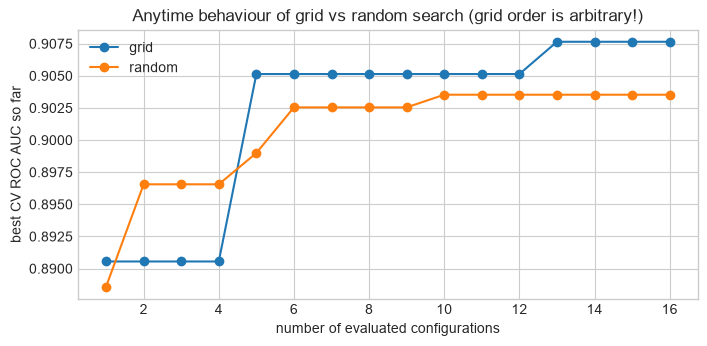

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, search in hgb_searches.items():
    scores = search.cv_results_["mean_test_score"]
    ax.plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores), marker="o", label=name)
ax.set_xlabel("number of evaluated configurations")
ax.set_ylabel("best CV ROC AUC so far")
ax.set_title("Anytime behaviour of grid vs random search (grid order is arbitrary!)")
ax.legend()
plt.show()

## Demo: Successive Halving on the Same Boosting Space {.scrollable}

Use training-row count as fidelity and start with 27 candidates. The initial sample size adapts to the dataset, including the smaller offline fallback. Inspect the actual `n_resources_` and `n_candidates_` schedule rather than assuming four rounds.

The final table distinguishes initial configurations from configuration/fidelity evaluations: promoted candidates are evaluated again. Its best CV scores can reflect different resource levels, so use the shared external validation partition for the final classroom comparison. This is not an equal-time benchmark.

In [11]:
halving = HalvingRandomSearchCV(
    hgb_pipeline,
    param_distributions,
    n_candidates=27,
    factor=3,
    resource="n_samples",
    min_resources=min(300, max(30, len(X_cls_train) // 9)),
    cv=hgb_cv,
    scoring="roc_auc",
    n_jobs=1,
    random_state=RANDOM_STATE,
)
started_at = time.time()
halving.fit(X_cls_train, y_cls_train)
halving_elapsed = time.time() - started_at

hgb_search_rows.append({
    "search": "successive halving",
    "n_configs": halving.n_candidates_[0],
    "cv_evaluations": len(halving.cv_results_["params"]),
    "elapsed_s": halving_elapsed,
    "best_cv_roc_auc": halving.best_score_,
    "validation_roc_auc": roc_auc_score(y_cls_val, halving.predict_proba(X_cls_val)[:, 1]),
})
for row in hgb_search_rows[:-1]:
    row["cv_evaluations"] = row["n_configs"]

display(pd.DataFrame({"iteration": range(halving.n_iterations_),
                      "candidates": halving.n_candidates_,
                      "rows_per_candidate": halving.n_resources_}))
pd.DataFrame(hgb_search_rows).round(4)

,iteration,candidates,rows_per_candidate
0,0,27,300
1,1,9,900
2,2,3,2700


,search,n_configs,elapsed_s,best_cv_roc_auc,validation_roc_auc,cv_evaluations
0,grid,16,18.7341,0.9076,0.9312,16
1,random,16,16.5601,0.9035,0.9253,16
2,successive halving,27,16.1798,0.8916,0.9197,39


### Budget Questions

1. How many initial configurations and how many candidate/fidelity evaluations did halving use?
2. How do its actual runtime and validation score compare with grid/random search?
3. Which boosting hyperparameters increase training cost?
4. When could early rankings on a small sample discard the eventual best candidate?
5. Why does the grid's arbitrary enumeration order affect its anytime curve?

## 4. FLAML for Classification {.scrollable}

We pass an explicit validation partition and the learner list `CLASSIFIERS`. `retrain_full=False` keeps validation rows out of fitting when we compare scores. The test partition stays sealed until the final evaluation. `time_budget` is defined in setup and recorded in the log filename.

Our existing helper maps categories to integer codes using **training data only**, reusing that map on validation/test data and assigning unseen values a distinct code. These codes impose an arbitrary ordering; they are a fixed teaching choice, not automated feature engineering. The manual baseline uses one-hot encoding, so the comparison changes both preprocessing and model search.

FLAML minimizes `1 - ROC AUC` for `metric="roc_auc"`; `best_loss` is a validation loss, not a test score. See the [FLAML task-oriented AutoML documentation](https://microsoft.github.io/FLAML/docs/Use-Cases/Task-Oriented-AutoML/).

In [12]:
classification_automl = AutoML()

classification_started_at = time.perf_counter()
classification_automl.fit(
    X_train=X_cls_train_flaml,
    y_train=y_cls_train,
    X_val=X_cls_val_flaml,
    y_val=y_cls_val,
    eval_method="holdout",
    retrain_full=False,
    estimator_list=CLASSIFIERS,
    n_jobs=1,
    task="classification",
    metric="roc_auc",
    time_budget=time_budget,
    log_file_name=f"flaml_main_classification_roc_auc_{time_budget}s.log",
    seed=RANDOM_STATE,
    verbose=1,
)
classification_elapsed = time.perf_counter() - classification_started_at

In [13]:
print(f"Best estimator: {classification_automl.best_estimator}")
print(f"Best validation loss: {classification_automl.best_loss:.6f}")
print(f"Training time for best config: {classification_automl.best_config_train_time:.3f}s")
classification_automl.best_config

Best estimator: rf
Best validation loss: 0.085389
Training time for best config: 2.188s


{'n_estimators': 481,
 'max_features': np.float64(0.5474533553524207),
 'max_leaves': 55,
 'criterion': np.str_('entropy')}

In [14]:
classification_automl_scores = evaluate_classifier(classification_automl, X_cls_val_flaml, y_cls_val)
display_scores("FLAML classification model", classification_automl_scores)
print("confusion matrix:")
print(confusion_matrix(y_cls_val, classification_automl.predict(X_cls_val_flaml)))

pd.DataFrame(
    [classification_baseline_scores, classification_automl_scores],
    index=["manual_baseline", "flaml"],
).round(3)

FLAML classification model
  accuracy: 0.866
  roc_auc : 0.915
  f1      : 0.659
confusion matrix:
[[1177   33]
 [ 182  208]]


,accuracy,roc_auc,f1
manual_baseline,0.866,0.908,0.685
flaml,0.866,0.915,0.659


## Inspect FLAML's Conditional CASH Space

The configured learner list defines allowed algorithms; `best_config_per_estimator` reports learners with recorded results, which can be fewer under a tight budget. Inspect the random-forest space used in our lab, including its default and low-cost initial values.

This is an inspection of a learner's declared space, not an exhaustive record of all settings actually visited.

In [15]:
from flaml.automl.model import RandomForestEstimator
from flaml.automl.task.factory import task_factory

print("Allowed learners:", CLASSIFIERS)
print("Learners with results:", list(classification_automl.best_config_per_estimator))

def describe_space(space):
    rows = []
    for name, spec in space.items():
        domain = spec["domain"]
        if hasattr(domain, "categories"):
            values = str(list(domain.categories))
        elif hasattr(domain, "lower") and hasattr(domain, "upper"):
            sampler = domain.get_sampler() if hasattr(domain, "get_sampler") else None
            values = f"[{domain.lower}, {domain.upper}] ({type(sampler).__name__})"
        else:
            values = str(domain)
        rows.append({"hyperparameter": name, "domain": values,
                     "init_value": spec.get("init_value"),
                     "low_cost_init_value": spec.get("low_cost_init_value")})
    return pd.DataFrame(rows)

display(describe_space(RandomForestEstimator.search_space(
    data_size=X_cls_train_flaml.shape,
    task=task_factory("classification", X_cls_train_flaml, y_cls_train)
)))

Allowed learners: ['rf', 'extra_tree', 'lrl2']
Learners with results: ['rf', 'extra_tree', 'lrl2']


,hyperparameter,domain,init_value,low_cost_init_value
0,n_estimators,"[4, 2048] (_LogUniform)",4.000000,4.0
1,max_features,"[0.1, 1.0] (_LogUniform)",0.267261,NaN
2,max_leaves,"[4, 2400] (_LogUniform)",4.000000,4.0
3,criterion,"['gini', 'entropy']",NaN,NaN


## FLAML Anytime Behavior from Its Log

Read the main classification run's own log, which has a distinct filename from the metric-comparison runs. Plot logged validation results per learner and the overall incumbent against elapsed time. For ROC AUC, transform loss back to score with `1 - loss`.

Default logs need not contain every attempted configuration; counts below describe logged records, not the total number of evaluations. Inspect a full trial log if you need complete accounting.

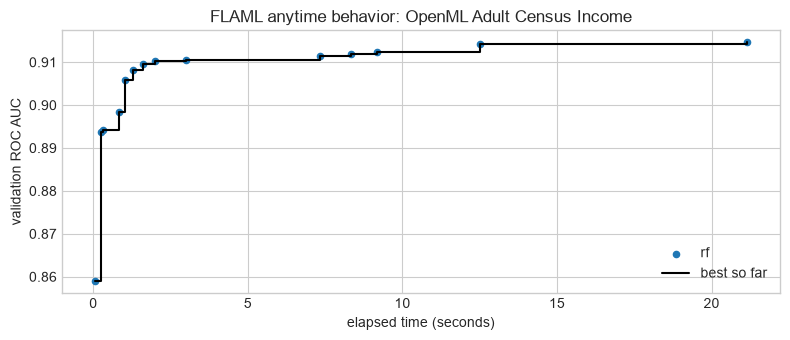

rf    14
Name: logged records per learner, dtype: int64

In [16]:
from flaml.automl.data import get_output_from_log

log_path = f"flaml_main_classification_roc_auc_{time_budget}s.log"
time_history, best_loss_history, loss_history, config_history, _ = get_output_from_log(
    filename=log_path, time_budget=float("inf")
)
learners = [record["Current Learner"] for record in config_history]
fig, ax = plt.subplots(figsize=(8, 3.5))
for learner in sorted(set(learners)):
    idx = [i for i, name in enumerate(learners) if name == learner]
    ax.scatter(np.asarray(time_history)[idx], 1 - np.asarray(loss_history)[idx], s=20, label=learner)
ax.step(time_history, 1 - np.asarray(best_loss_history), where="post", color="black", label="best so far")
ax.set(xlabel="elapsed time (seconds)", ylabel="validation ROC AUC", title=f"FLAML anytime behavior: {adult_source}")
ax.legend()
plt.tight_layout()
plt.show()
display(pd.Series(learners, dtype="object").value_counts().rename("logged records per learner"))

## 5. Classification Metrics

On Adult Income, accuracy can look good even when the model performs poorly on the minority class.

Run the same AutoML procedure with different optimization metrics and compare the validation results; choose the objective before opening the test set.

In [17]:
def run_flaml_classification(metric="roc_auc", time_budget=time_budget):
    model = AutoML()
    started_at = time.time()
    model.fit(
        X_train=X_cls_train_flaml,
        y_train=y_cls_train,
        X_val=X_cls_val_flaml,
        y_val=y_cls_val,
        eval_method="holdout",
        retrain_full=False,
        estimator_list=CLASSIFIERS,
        n_jobs=1,
        task="classification",
        metric=metric,
        time_budget=time_budget,
        log_file_name=f"flaml_adult_{metric}_{time_budget}s.log",
        seed=RANDOM_STATE,
        verbose=0,
    )
    elapsed = time.time() - started_at
    scores = evaluate_classifier(model, X_cls_val_flaml, y_cls_val)
    return {
        "metric": metric,
        "budget": time_budget,
        "elapsed": elapsed,
        "best_estimator": model.best_estimator,
        "best_loss": model.best_loss,
        **scores,
    }


classification_metric_results = pd.DataFrame(
    [run_flaml_classification(metric=m, time_budget=time_budget) for m in ["accuracy", "roc_auc", "f1"]]
)
classification_metric_results.round(3)

,metric,budget,elapsed,best_estimator,best_loss,accuracy,roc_auc,f1
0,accuracy,30,30.066,rf,0.120,0.880,0.913,0.711
1,roc_auc,30,30.003,rf,0.086,0.866,0.914,0.661
2,f1,30,30.005,rf,0.311,0.870,0.900,0.689


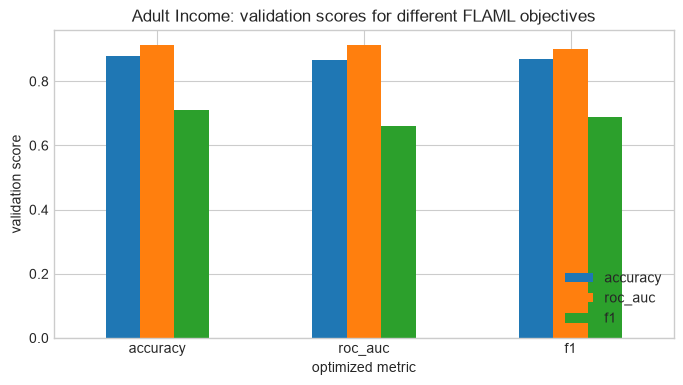

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
classification_metric_results.set_index("metric")[["accuracy", "roc_auc", "f1"]].plot(kind="bar", ax=ax)
ax.set_title("Adult Income: validation scores for different FLAML objectives")
ax.set_xlabel("optimized metric")
ax.set_ylabel("validation score")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.show()

### Classification Questions

1. Which metric selected the strongest model for ROC AUC?
2. Which metric selected the strongest model for F1?
3. Which errors are more costly in this task?
4. What additional fairness or governance checks would you run before deployment?

## 6. Regression Dataset: California Housing

The second real dataset is California Housing, originally derived from the 1990 US census.

The task is to predict median house value for California districts from demographic and geographic attributes.

This gives us a second AutoML setting: regression rather than classification.

In [19]:
def load_housing_data():
    try:
        housing = fetch_california_housing(as_frame=True)
        return housing.frame.copy(), "California Housing"
    except Exception as exc:
        print(f"Could not download California Housing: {exc}")
        print("Falling back to the real built-in diabetes regression dataset.")
        diabetes = load_diabetes(as_frame=True)
        df = diabetes.frame.copy()
        df = df.rename(columns={"target": "MedHouseVal"})
        return df, "scikit-learn diabetes fallback"


housing_df, housing_source = load_housing_data()
print(housing_source)
display(housing_df.head())
display(housing_df.describe().T[["mean", "std", "min", "max"]].round(3))

Could not download California Housing: Remote end closed connection without response
Falling back to the real built-in diabetes regression dataset.
scikit-learn diabetes fallback


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,MedHouseVal
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,mean,std,min,max
age,-0.000,0.048,-0.107,0.111
sex,0.000,0.048,-0.045,0.051
bmi,-0.000,0.048,-0.090,0.171
bp,-0.000,0.048,-0.112,0.132
s1,-0.000,0.048,-0.127,0.154
s2,0.000,0.048,-0.116,0.199
s3,-0.000,0.048,-0.102,0.181
s4,-0.000,0.048,-0.076,0.185
s5,0.000,0.048,-0.126,0.134
s6,0.000,0.048,-0.138,0.136


In [20]:
regression_target = "MedHouseVal" if "MedHouseVal" in housing_df.columns else "target"
X_reg = housing_df.drop(columns=[regression_target])
y_reg = housing_df[regression_target]

X_reg_dev, X_reg_test, y_reg_dev, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg_dev, y_reg_dev, test_size=0.25, random_state=RANDOM_STATE
)

X_reg_val_flaml, _ = prepare_flaml_frame(X_reg_val, categorical_columns=[])
X_reg_train_flaml, _ = prepare_flaml_frame(X_reg_train, categorical_columns=[])
X_reg_test_flaml, _ = prepare_flaml_frame(X_reg_test, categorical_columns=[])

print(f"Rows: {len(X_reg)}")
print(f"Features: {X_reg.shape[1]}")
print(f"Target: {regression_target}")

Rows: 442
Features: 10
Target: MedHouseVal


## 7. Manual Regression Baselines

We compare FLAML against two common baselines:

- Ridge regression: simple, fast, and linear.
- Random forest: nonlinear and stronger, but less transparent and more expensive.

In [21]:
ridge_baseline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=1.0)),
    ]
)
forest_baseline = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

ridge_baseline.fit(X_reg_train, y_reg_train)
forest_baseline.fit(X_reg_train, y_reg_train)

ridge_scores = evaluate_regressor(ridge_baseline, X_reg_val, y_reg_val)
forest_scores = evaluate_regressor(forest_baseline, X_reg_val, y_reg_val)

display_scores("Ridge regression baseline", ridge_scores)
display_scores("Random forest baseline", forest_scores)

pd.DataFrame([ridge_scores, forest_scores], index=["ridge", "random_forest"]).round(3)

Ridge regression baseline
  rmse    : 51.103
  mae     : 42.723
  r2      : 0.523
Random forest baseline
  rmse    : 54.077
  mae     : 44.025
  r2      : 0.466


,rmse,mae,r2
ridge,51.103,42.723,0.523
random_forest,54.077,44.025,0.466


## 8. FLAML for Regression

For regression, FLAML can optimize metrics such as RMSE, MAE, or R2.

Here we optimize RMSE and compare the selected model with the two manual baselines.

In [22]:
regression_automl = AutoML()

regression_started_at = time.perf_counter()
regression_automl.fit(
    X_train=X_reg_train_flaml,
    y_train=y_reg_train,
    X_val=X_reg_val_flaml,
    y_val=y_reg_val,
    eval_method="holdout",
    retrain_full=False,
    estimator_list=REGRESSORS,
    n_jobs=1,
    task="regression",
    metric="rmse",
    time_budget=time_budget,
    log_file_name=f"flaml_main_regression_rmse_{time_budget}s.log",
    seed=RANDOM_STATE,
    verbose=1,
)
regression_elapsed = time.perf_counter() - regression_started_at

In [23]:
print(f"Best estimator: {regression_automl.best_estimator}")
print(f"Best validation loss: {regression_automl.best_loss:.6f}")
print(f"Training time for best config: {regression_automl.best_config_train_time:.3f}s")
regression_automl.best_config

Best estimator: extra_tree
Best validation loss: 50.478035
Training time for best config: 0.030s


{'n_estimators': 15,
 'max_features': np.float64(0.8962333412532528),
 'max_leaves': 131}

In [24]:
regression_automl_scores = evaluate_regressor(regression_automl, X_reg_val_flaml, y_reg_val)
display_scores("FLAML regression model", regression_automl_scores)

pd.DataFrame(
    [ridge_scores, forest_scores, regression_automl_scores],
    index=["ridge", "random_forest", "flaml"],
).round(3)

FLAML regression model
  rmse    : 50.478
  mae     : 41.961
  r2      : 0.535


,rmse,mae,r2
ridge,51.103,42.723,0.523
random_forest,54.077,44.025,0.466
flaml,50.478,41.961,0.535


## Multi-Fidelity Search

A multi-fidelity strategy evaluates many configurations cheaply, then spends more resources on promising ones.

## Fidelity Means Resource Level

| Low fidelity | Higher fidelity |
| --- | --- |
| fewer rows | more rows |
| fewer trees | more trees |
| fewer epochs | more epochs |
| shorter training | longer training |

FLAML's design is in the same spirit: good anytime behavior matters because the search may be stopped by a fixed budget.

## 9. Budget Experiment

Repeat FLAML on regression using `budget_values` from setup. All runs use the same validation partition and learner list. Record elapsed time and validation RMSE; do not choose a budget by inspecting test results.

These are independent restarts, not checkpoints of one search. Longer budgets need not yield monotonically better results because search paths and runtime vary. For a stronger experiment, repeat across seeds and report score/time variability. The budget covers each `fit` call; data loading and the manual baselines are additional costs.

In [25]:
def run_flaml_regression(time_budget=time_budget, metric="rmse"):
    model = AutoML()
    started_at = time.time()
    model.fit(
        X_train=X_reg_train_flaml,
        y_train=y_reg_train,
        X_val=X_reg_val_flaml,
        y_val=y_reg_val,
        eval_method="holdout",
        retrain_full=False,
        estimator_list=REGRESSORS,
        n_jobs=1,
        task="regression",
        metric=metric,
        time_budget=time_budget,
        log_file_name=f"flaml_housing_{metric}_{time_budget}s.log",
        seed=RANDOM_STATE,
        verbose=0,
    )
    elapsed = time.time() - started_at
    scores = evaluate_regressor(model, X_reg_val_flaml, y_reg_val)
    return {
        "budget": time_budget,
        "metric": metric,
        "elapsed": elapsed,
        "best_estimator": model.best_estimator,
        "best_loss": model.best_loss,
        **scores,
    }


regression_budget_results = pd.DataFrame(
    [run_flaml_regression(time_budget=b, metric="rmse") for b in budget_values]
)
regression_budget_results.round(3)

,budget,metric,elapsed,best_estimator,best_loss,rmse,mae,r2
0,5,rmse,4.984,extra_tree,51.801,51.801,44.194,0.510
1,15,rmse,15.002,extra_tree,50.825,50.825,42.268,0.529
2,30,rmse,29.984,extra_tree,50.478,50.478,41.961,0.535


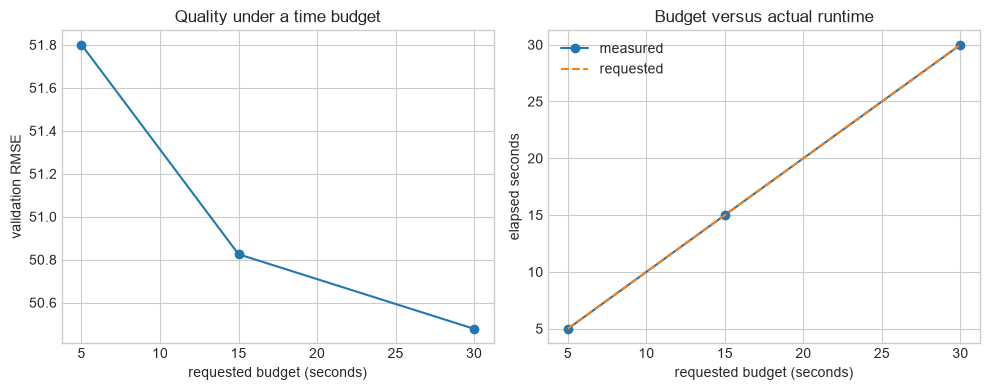

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(regression_budget_results["budget"], regression_budget_results["best_loss"], marker="o")
axes[0].set(xlabel="requested budget (seconds)", ylabel="validation RMSE", title="Quality under a time budget")
axes[1].plot(regression_budget_results["budget"], regression_budget_results["elapsed"], marker="o", label="measured")
axes[1].plot(budget_values, budget_values, linestyle="--", label="requested")
axes[1].set(xlabel="requested budget (seconds)", ylabel="elapsed seconds", title="Budget versus actual runtime")
axes[1].legend()
plt.tight_layout()
plt.show()

## Interpreting the Budget Experiment

Increasing a budget changes the search opportunity, not the task definition. Explain the observed tradeoff using validation quality, elapsed time, and selected estimator. If two budgets give similar validation scores, discuss whether the extra compute is justified.

Within one run, the best observed loss on a fixed validation objective cannot increase as more completed trials are added. This does not guarantee that independent runs, low-fidelity scores, or final test performance improve monotonically.

## Budget Is a Modeling Decision

A system that is excellent after two hours may not be the best choice for an interactive workflow that allows only two minutes.

When reporting AutoML results, always state the time budget together with the chosen metric and selected model.

## 10. Inspect, Freeze, Then Evaluate

Inspect `best_estimator`, `best_config`, `best_loss`, and the saved logs. Explain which parts of the search were fixed by us and which FLAML selected. Freeze the two main runs before executing the final test cell below.

The earlier baseline and search tables contain validation scores. The final table contains test scores for the two pre-specified FLAML runs. Keep that distinction explicit in the report.

## Reproducibility Checklist

- dataset name and version;
- feature preprocessing and missing-value handling;
- training/validation/test splits and random seed;
- task type and optimized metric;
- requested time budget and measured elapsed time;
- library versions and available hardware/parallelism;
- selected learner;
- best validation loss;
- best configuration;
- final test-set metrics.

AutoML is most useful when its choices are inspectable and reproducible.

In [27]:
# Final evaluation: run only after fixing the metric, search space, and budget.
# Report these two pre-specified main runs; do not select another run from test scores.
classification_final_scores = evaluate_classifier(classification_automl, X_cls_test_flaml, y_cls_test)
regression_final_scores = evaluate_regressor(regression_automl, X_reg_test_flaml, y_reg_test)
summary = pd.DataFrame([
    {"task": "classification", "dataset": adult_source, "optimized_metric": "roc_auc",
     "budget_seconds": time_budget, "elapsed_seconds": classification_elapsed, "best_estimator": classification_automl.best_estimator,
     "validation_loss": classification_automl.best_loss, **classification_final_scores},
    {"task": "regression", "dataset": housing_source, "optimized_metric": "rmse",
     "budget_seconds": time_budget, "elapsed_seconds": regression_elapsed, "best_estimator": regression_automl.best_estimator,
     "validation_loss": regression_automl.best_loss, **regression_final_scores},
])
summary.round(3)

,task,dataset,optimized_metric,budget_seconds,elapsed_seconds,best_estimator,validation_loss,accuracy,roc_auc,f1,rmse,mae,r2
0,classification,OpenML Adult Census Income,roc_auc,30,30.028,rf,0.085,0.854,0.902,0.645,NaN,NaN,NaN
1,regression,scikit-learn diabetes fallback,rmse,30,30.001,extra_tree,50.478,NaN,NaN,NaN,55.777,44.382,0.413


# End-to-End Pipeline Optimization

## 11. From CASH to End-to-End Pipeline Optimization {.scrollable}

So far, we fixed data cleaning, category encoding, feature availability, and validation design, then searched over learners. End-to-end pipeline optimization also searches over the **structure and operations** that turn raw data into predictions.

Let $s$ denote a pipeline structure, $\theta\in\Theta_s$ its conditional settings, and $\mathcal S(C)$ the structures allowed by human constraints $C$:

$$ (s^*,\theta^*)\in\arg\min_{s\in\mathcal S(C),\;\theta\in\Theta_s}
\widehat{\mathcal L}_{\mathrm{val}}\!\left(\operatorname{Fit}(P_{s,\theta},D_{\mathrm{tr}})\right),
\qquad c_{\mathrm{search}}\le B. $$

The pipeline may choose imputation → encoding → feature construction/selection → resampling → learner → calibration. Structure can be a sequence or a graph; changing an early step changes the meaning and cost of later choices.

## Why Full Pipeline Search Is Harder {.scrollable}

- **Dependencies:** scaling matters for some learners; SMOTE must follow a suitable representation and stay inside training folds.
- **Data quality:** deletion, imputation, and feature construction can change who is represented and what the model learns.
- **Constraints:** accuracy competes with latency, fairness, interpretability, and resource limits; some pipelines are inadmissible even if accurate.
- **Evaluation:** more trials increase validation overfitting; learned transformations must be refitted inside each training split.
- **Control and provenance:** record data versions, transformations, constraints, code, and failures so humans can understand and revise a result.

Connect this to Labs 01–03: augmentation, feature selection, and fairness can become pipeline choices. A fixed metric and valid evaluation protocol remain prerequisites; searching for a favorable validation split would undermine the objective.

Even before selecting operators, allowing each of $s$ step types at most once gives $\sum_{m=0}^{s} s!/(s-m)!$ ordered structures: 326 when $s=5$. This is an illustrative unrestricted count; type and domain constraints remove many structures. Scaling before a tree is often unnecessary, rather than invalid. [TPOT](https://arxiv.org/abs/1603.06212) explores pipeline structures using genetic programming, illustrating a different scope from fixed-template search.

References: [@olson2016evaluation].

## Preprocessing Order Is a Search Decision

[Giovanelli, Bilalli, and Abelló (2021), *Effective data pre-processing for AutoML*](https://ceur-ws.org/Vol-2840/paper1.pdf) study transformations and combinations of transformations as **pipeline prototypes** [@giovanelli2021effective]. Choosing a promising prototype comes before tuning the operators that instantiate it.

Distinguish three decisions:

1. **Structure:** which step types are present and in which order.
2. **Operators:** which implementation fills each step.
3. **Hyperparameters:** how each operator and learner is configured.

For example, feature selection can change the neighborhood on which later resampling operates; reversing the steps changes the data seen by the selector. Both choices must still fit selection and resampling strictly inside training folds.

**Exercise:** propose two admissible orders for feature selection and resampling, identify an assumption behind each, and explain how you would compare them under one budget and evaluation protocol.

## HAMLET: Human Knowledge Shapes the Search {.scrollable}

[Francia et al. (2023), *HAMLET: A framework for Human-centered AutoML via Structured Argumentation*](https://www.sciencedirect.com/science/article/pii/S0167739X22004393) connects AutoML with explicit human knowledge and constraints. The data scientist expresses constraints in a logical knowledge base, represented through a Problem Graph. Structured argumentation makes conflicts between rules and pipeline choices explicit when deriving the admissible search space. [Author repository](https://cris.unibo.it/handle/11585/913288).

The teaching question shifts from “Which model won?” to “Which alternatives were allowed, and why?” In our lab, consider a rule requiring interpretable learners or prohibiting a feature. Where should that rule enter the search, and how should its effect be explained?

**Discussion:** distinguish a hard admissibility constraint from a preference that can trade off against predictive performance.

The explored configurations can also be mined to recommend new rules for the user to inspect and accept or reject. Recommendations reflect the explored data and search history, rather than universally valid preprocessing rules.

An iterative workflow makes the human role concrete: encode rules → derive an admissible space → search → inspect evidence → revise rules. Separate data constraints (forbidden features), ordering constraints (which preprocessing step may follow another), and learner requirements (such as suitable scaling for distance-based methods).

References: [@francia2023hamlet].

## MLZero: Agents Build and Repair ML Workflows {.scrollable}

[Fang et al. (NeurIPS 2025), *MLZero: A Multi-Agent System for End-to-end Machine Learning Automation*](https://neurips.cc/virtual/2025/poster/119504) uses LLM-powered agents to automate workflows across data modalities. A perception module turns raw multimodal inputs into task context. Agents generate code, execute it, inspect failures, and revise the workflow. Semantic memory supplies reusable knowledge, while episodic memory retains earlier attempts and errors to help reduce hallucinated or outdated API calls.

This expands the action space beyond choosing values in a prewritten estimator configuration: agents generate and revise executable workflows. The paper evaluates MLE-Bench Lite and a 25-task multimodal AutoML agent benchmark, and also reports experiments with a compact 8B LLM; those results do not establish reliability on every deployment task.

**Discussion:** if an agent writes preprocessing code for Adult Income, which execution checks and independent validation would detect leakage, invalid assumptions, or an apparently successful but wrong solution?

References: [@fang2025mlzero].

## AGE-ML: Specifications for Data-Centric AutoML

[Matteini et al. (ADBIS 2026), *Agentic Architecture for Data-Centric AutoML*](https://adbis26.sciencesconf.org/753016) presents AGE-ML, a specification-driven architecture. Human-readable assumptions, constraints, evaluation criteria, and preferences define a pipeline search space; an LLM agent loop generates and validates pipelines and provides structured explanations.

The linked conference abstract emphasizes controllability, traceability, reproducibility, and iterative refinement. Use it as an architectural research reference; it does not provide enough detail on that page to reproduce the experiments or infer numerical improvements.

**Discussion:** write a specification for our classification task: target, permitted features, missing-value policy, split protocol, objective, budget, and explanation requirements. Which parts could a validator check automatically?

References: [@matteini2026agentic].

## Compare the Boundaries of Automation {.scrollable}

| Approach | What can change? | What should the human inspect? |
| --- | --- | --- |
| HPO | Hyperparameters of a fixed learner | Bounds, sampling distributions, evaluation |
| CASH / our FLAML example | Learner and its hyperparameters | Learner list, budget allocation, selected configuration |
| Full pipeline search | Preprocessing, features, structure, learner | Leakage, admissible operations, constraints |
| HAMLET | Search space informed by knowledge and argumentation | Rules, Problem Graph, revisions |
| MLZero | Agent-generated and iteratively repaired workflows | Generated code, execution evidence, validation |
| AGE-ML | Pipelines generated from explicit specifications | Specification compliance, provenance, explanations |

These approaches address different aspects of automation. This table compares their scope; it is not a performance ranking.

Also compare the risks: fixed search spaces can exclude useful solutions; rule-based systems require knowledge engineering; code-generating agents need execution checks; specification-driven systems depend on the quality of the specification. Which evidence and human controls would you require in a lending application? Adult Income itself is an income-prediction dataset, not a creditworthiness label.

## Demo: Human Constraints Shape an Executable Search {.scrollable}

Turn a small human-readable specification into a feature filter and FLAML settings. Compare a reference specification with an otherwise identical specification that forbids `sex`, `race`, and `native_country`. Both use F1, the same learner list, budget, seed, and validation partition, so the intended changed factor is feature admissibility. Runtime-limited searches can still follow different paths.

This is an illustration of applying a specification, not an implementation of HAMLET or an LLM agent. Attribute removal does not guarantee fairness: proxies and unequal error rates can remain. On the offline fallback, these attributes are absent, so the feature restriction is a no-op; adapt it to a relevant feature to study a real intervention.

In [28]:
reference_spec = {
    "forbidden_features": [], "learners": CLASSIFIERS.copy(),
    "metric": "f1", "time_budget": time_budget,
}
restricted_spec = {**reference_spec, "forbidden_features": ["sex", "race", "native_country"]}

def run_flaml_from_spec(spec, label):
    kept = [name for name in X_cls_train.columns if name not in spec["forbidden_features"]]
    if not kept:
        raise ValueError("The specification must retain at least one feature.")
    kept_cat = [name for name in categorical_cls if name in kept]
    X_tr, maps = prepare_flaml_frame(X_cls_train[kept], kept_cat)
    X_va, _ = prepare_flaml_frame(X_cls_val[kept], kept_cat, maps)
    model = AutoML()
    started_at = time.perf_counter()
    model.fit(
        X_train=X_tr, y_train=y_cls_train, X_val=X_va, y_val=y_cls_val,
        eval_method="holdout", retrain_full=False, task="classification",
        metric=spec["metric"], estimator_list=spec["learners"], n_jobs=1,
        time_budget=spec["time_budget"], seed=RANDOM_STATE, verbose=0,
        log_file_name=f"flaml_spec_{label}_{spec['time_budget']}s.log",
    )
    return {"run": label, "n_features": len(kept),
            "removed_features": [name for name in X_cls_train.columns if name not in kept],
            "budget_seconds": spec["time_budget"], "elapsed_seconds": time.perf_counter() - started_at,
            "best_estimator": model.best_estimator, "best_loss": model.best_loss,
            **evaluate_classifier(model, X_va, y_cls_val)}

spec_results = pd.DataFrame([
    run_flaml_from_spec(reference_spec, "reference"),
    run_flaml_from_spec(restricted_spec, "restricted"),
])
display(spec_results.round(3))

,run,n_features,removed_features,budget_seconds,elapsed_seconds,best_estimator,best_loss,accuracy,roc_auc,f1
0,reference,14,[],30,29.986,rf,0.311,0.870,0.9,0.689
1,restricted,11,"[race, sex, native_country]",30,30.002,extra_tree,0.310,0.865,0.9,0.690


### Pipeline Questions

1. Which requirements constrain the data, and which constrain the model or evaluation?
2. Which proxies could retain information about an excluded attribute?
3. Write two HAMLET-style admissibility or ordering rules for preprocessing.
4. What would an agent need to inspect to generate a valid pipeline without leakage?
5. How would experiment tracking show that a pipeline complied with its specification?

### Design Exercise: Automate One More Decision

Starting from our FLAML example, choose one currently manual operation: missing-value handling, encoding, feature selection, or resampling.

1. Define two admissible alternatives and their conditional parameters.
2. Explain how each alternative is fitted without leaking validation data.
3. State a metric, a total budget, and one human constraint.
4. Specify the evidence needed to accept, explain, and reproduce the selected pipeline.
5. Use HAMLET, MLZero, or AGE-ML to explain how a human could inspect or revise that decision.

A design and pseudocode are sufficient; implementing an agent system is outside this lab's practical scope.

# Wrap-Up

## What AutoML Automates

AutoML can automate repetitive parts of modeling:

- trying candidate learners;
- allocating trials;
- tuning hyperparameters;
- returning a strong baseline.

## What AutoML Does Not Automate

AutoML does not remove the data-science responsibility for:

- problem formulation;
- target definition;
- leakage checks;
- fairness assessment;
- deployment monitoring;
- deciding whether a model should be used at all.

A good AutoML report explains both the machine-selected model and the human choices that shaped the search.

## Final Exercise: AutoML Audit Memo

Write a one-page audit memo for one FLAML model from this notebook.

Your memo should help a reader decide whether the model is a useful baseline, a deployable model, or only an exploratory result.

## Audit Memo Prompts

Answer these questions:

1. What exact task, metric, and time budget did FLAML optimize, and how long did it actually run?
2. Which model did FLAML select, and how did it compare with the manual baseline and grid/random search on validation data?
3. What evidence suggests the result is reliable, and how was the test set kept sealed?
4. What evidence is still missing before deployment?
5. Which human modeling choice had the largest effect on the conclusion?

## Deliverables

Submit a short lab report with the core experimental results and your interpretation.

## Report Checklist {.scrollable}

1. HPO and CASH objectives, including their search spaces and evaluation protocol.
2. Grid/random-search results: candidate counts, CV scores, validation scores, and elapsed times; explain why random search can work.
3. Manual and FLAML validation results for classification and regression, naming the actual datasets if fallbacks were used.
4. Classification metric comparison and regression budget comparison, with measured runtime.
5. Final test results for the two pre-specified main FLAML runs, clearly separated from selection results.
6. An end-to-end pipeline proposal linked to one of HAMLET, MLZero, or AGE-ML, plus the audit memo.
7. If running the extended demonstrations, include boosting grid/random/halving results, resource schedules, the FLAML anytime plot, and the matched constraint comparison.
8. Write a short position on human-centered versus agentic AutoML, including who defines the space and how choices can be revised.

Explain what was automated, what was fixed manually, and which evidence remains missing.

## Extension Tasks

Choose one if you finish early:

- Add `estimator_list=["lgbm", "xgboost", "rf", "extra_tree"]` after installing the optional learners.
- Save and reload an AutoML run with `automl.pickle()` and `AutoML.load_pickle()`.
- Repeat the classification task with a fairness-sensitive subgroup comparison.
- Add a Bayesian-optimization baseline under the same resource accounting.
- Compare a single-learner FLAML run with the multi-learner run using logged curves.
- Extend the specification demo with a fold-safe imputation or resampling choice; express it as a custom pipeline objective for `flaml.tune`.

## More Extension Tasks

- Create a custom metric that penalizes false negatives more heavily than false positives.
- Repeat the budget experiment across several seeds and report score/runtime variability.
- Repeat the regression budget experiment with MAE instead of RMSE.
- Summarize how the selected learner changes as the budget increases.

## References {.scrollable}

::: {#refs}
:::

## Practical Resources

- [FLAML: Task-Oriented AutoML](https://microsoft.github.io/FLAML/docs/Use-Cases/Task-Oriented-AutoML/).
- [scikit-learn: hyperparameter search](https://scikit-learn.org/stable/modules/grid_search.html).
- [UCI Adult dataset](https://archive.ics.uci.edu/dataset/2/adult).
- [scikit-learn California Housing](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html).

The bibliography uses the same `refs/refs.bib` and Quarto/Pandoc citation mechanism as Lab 03. Research figures retain their source attribution to the Hutter–Vanschoren tutorial and the cited papers. Direct paper links remain in the explanations for notebook readers.